# 03 · Resume and evaluate the baseline U-Net on Colab

Continue the Kaggle training run on Colab, compare the best and latest checkpoints, and preview generated frames. With the current `EPOCHS=10`, a completed epoch-10 checkpoint goes straight to evaluation.

**Setup:** Place the Stage 1 and Stage 2 ZIPs in the configured Drive folder. Select a GPU or TPU. Increase `EPOCHS` to continue training.

**Saves:** Training checkpoints, validation reports, image panels, animations, and verified ZIP backups.

In [1]:
from pathlib import Path

EPOCHS = 10
COMPARE_LATEST = True
RUN_TEST = False
MAKE_RECURSIVE_PREVIEW = False
RUN_RECURSIVE_VALIDATION = False
RUN_RECURSIVE_TEST = False

PROJECT = Path("/content/drive/MyDrive/Interframes")
STAGE1_ZIP = PROJECT / "interframes_tf_stage1.zip"
STAGE2_INPUT = PROJECT / "interframes_tf_stage2.zip"
WORK_ROOT = Path("/content")
DURABLE_BACKUP_DIR = PROJECT / "interframes_tf_stage2" / "models_checkpoints"
OUT = WORK_ROOT / "interframes_tf_stage2"
BACKUP_ZIP = WORK_ROOT / "interframes_stage2_backup.zip"

## Connect Drive and select the device

Mount Drive and detect the GPU or TPU.

In [2]:
import os, sys, json, shutil, hashlib, zipfile, time
from pathlib import Path

os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import FileLink, HTML, display

from google.colab import drive

drive.mount("/content/drive")


gpus = tf.config.list_physical_devices("GPU")
has_tpu = any(
    os.environ.get(key)
    for key in (
        "TPU_NAME",
        "COLAB_TPU_ADDR",
        "TPU_WORKER_ID",
        "TPU_WORKER_HOSTNAMES",
        "TPU_ACCELERATOR_TYPE",
    )
)
if gpus:
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass
    tf.config.experimental.enable_tensor_float_32_execution(False)
    device_kind = "GPU"
    STRATEGY = tf.distribute.get_strategy()
elif has_tpu:
    if "_tpu_strategy" not in globals():
        try:
            resolver = tf.distribute.cluster_resolver.TPUClusterResolver()
        except ValueError:
            resolver = tf.distribute.cluster_resolver.TPUClusterResolver(tpu="local")
        tf.config.experimental_connect_to_cluster(resolver)
        tf.tpu.experimental.initialize_tpu_system(resolver)
        _tpu_strategy = tf.distribute.TPUStrategy(resolver)
    device_kind = "TPU"
    STRATEGY = _tpu_strategy
else:
    device_kind = "CPU"
    STRATEGY = tf.distribute.get_strategy()
print(
    "TensorFlow",
    tf.__version__,
    "| Keras",
    keras.__version__,
    "| Device:",
    device_kind,
    flush=True,
)
if gpus:
    print(
        "GPU:",
        tf.config.experimental.get_device_details(gpus[0]).get(
            "device_name", gpus[0].name
        ),
    )

ENVIRONMENT = "colab_" + device_kind.lower()

Mounted at /content/drive
TensorFlow 2.21.0 | Keras 3.13.2 | Device: GPU
GPU: Tesla T4


## Set memory and checkpoint limits

Set image-cache size, CPU workers, and save frequency.

In [3]:
def available_ram_gib():
    values = []
    try:
        import psutil

        values.append(psutil.virtual_memory().total / 1024**3)
    except ImportError:
        values.append(12.0)
    for path in [
        "/sys/fs/cgroup/memory.max",
        "/sys/fs/cgroup/memory/memory.limit_in_bytes",
    ]:
        try:
            value = Path(path).read_text().strip()
            if value.isdigit() and 0 < int(value) < 1024**5:
                values.append(int(value) / 1024**3)
        except OSError:
            pass
    return min(values)


IMAGE_CACHE_GIB = round(max(0.5, min(10.0, available_ram_gib() * 0.30)), 1)
CPU_WORKERS = max(1, min(4, (os.cpu_count() or 2) // 2))
CHECKPOINT_EVERY_BATCHES = 100 if device_kind == "TPU" else 1000
TPU_BATCH_SIZE = 8 * STRATEGY.num_replicas_in_sync
LINE_THRESHOLD = 0.5
LINE_TOLERANCE_PX = 2
print(
    f"Image cache: {IMAGE_CACHE_GIB} GiB | CPU workers: {CPU_WORKERS} | checkpoint interval: {CHECKPOINT_EVERY_BATCHES} batches"
)

Image cache: 3.8 GiB | CPU workers: 1 | checkpoint interval: 1000 batches


## Define archive and resume helpers

Define ZIP extraction, file checks, and checkpoint selection.

In [4]:
from tqdm.auto import tqdm


def read_json_file(path):
    return json.loads(Path(path).read_text())


def rank_state(state):
    p = state.get("partial") or {}
    return (
        int(state["completed_epochs"]),
        int(p.get("samples", 0)),
        int(state.get("optimizer_iterations", 0)),
    )


def marker_in_zip(archive, filename):
    matches = [
        n
        for n in archive.namelist()
        if Path(n).name == filename and "_checkpoints" not in Path(n).parts
    ]
    if len(matches) != 1:
        raise ValueError(
            f"ZIP must contain one top-level {filename}; found {matches[:5]}"
        )
    return matches[0]


def safe_extract(archive, destination):
    destination = Path(destination).resolve()
    for info in archive.infolist():
        p = Path(info.filename)
        target = (destination / p).resolve()
        if p.is_absolute() or ".." in p.parts or not target.is_relative_to(destination):
            raise ValueError(f"Unsafe archive path: {info.filename}")
        if (info.external_attr >> 16) & 0o170000 == 0o120000:
            raise ValueError("Symlinks are not accepted in checkpoint/data ZIPs.")
    for info in tqdm(archive.infolist(), desc="Extracting locally", unit="entry"):
        archive.extract(info, destination)


def unpack_bundle(source, cache, marker):
    source, cache = Path(source), Path(cache)
    with zipfile.ZipFile(source) as archive:
        member = marker_in_zip(archive, marker)
        signature = hashlib.sha256(
            "\n".join(
                f"{i.filename}:{i.CRC}:{i.file_size}" for i in archive.infolist()
            ).encode()
        ).hexdigest()
        ready = cache / "extraction_complete.json"
        if not ready.is_file() or read_json_file(ready).get("signature") != signature:
            temporary = cache.with_name(cache.name + ".extracting")
            if temporary.exists():
                shutil.rmtree(temporary)
            temporary.mkdir(parents=True)
            print(
                "Extracting ALL ZIP contents to local runtime storage:",
                source,
                flush=True,
            )
            local_zip = temporary.with_name(temporary.name + ".zip")
            try:
                print("Reading ZIP from", source, flush=True)
                with source.open("rb") as incoming, local_zip.open("wb") as outgoing:
                    with tqdm(
                        total=source.stat().st_size,
                        unit="B",
                        unit_scale=True,
                        desc="Copying ZIP",
                    ) as progress:
                        while chunk := incoming.read(8 * 1024**2):
                            outgoing.write(chunk)
                            progress.update(len(chunk))
                with zipfile.ZipFile(local_zip) as local_archive:
                    safe_extract(local_archive, temporary)
            finally:
                local_zip.unlink(missing_ok=True)
            (temporary / "extraction_complete.json").write_text(
                json.dumps(dict(signature=signature))
            )
            if cache.exists():
                shutil.rmtree(cache)
            temporary.replace(cache)
        return cache / Path(member).parent

## Open the prepared dataset

Extract Stage 1 locally, reusing a completed extraction.

In [5]:
if not STAGE1_ZIP.is_file():
    raise FileNotFoundError(f"Stage 1 ZIP missing: {STAGE1_ZIP}")
DATA_ROOT = unpack_bundle(
    STAGE1_ZIP, WORK_ROOT / "interframes_stage1_local", "stage1_complete.json"
)
marker = DATA_ROOT / "stage1_complete.json"
if not marker.is_file():
    raise FileNotFoundError(f"Stage 1 completion marker missing: {marker}")
meta = read_json_file(marker)
print("Stage 1:", DATA_ROOT, "| triplets:", meta["triplets"])

Extracting ALL ZIP contents to local runtime storage: /content/drive/MyDrive/Interframes/interframes_tf_stage1.zip
Reading ZIP from /content/drive/MyDrive/Interframes/interframes_tf_stage1.zip


Copying ZIP:   0%|          | 0.00/1.68G [00:00<?, ?B/s]

Extracting locally:   0%|          | 0/48099 [00:00<?, ?entry/s]

Stage 1: /content/interframes_stage1_local/interframes_tf_stage1 | triplets: {'test': 53290, 'train': 58390, 'val': 29188}


## Select a saved run

Copy a matching checkpoint into writable local storage.

In [6]:
def compatible(state):
    return state.get("run_config", {}).get("data_fingerprint") == meta["fingerprint"]


# Collect matching checkpoints without recursively listing every frame on Google Drive.
choices = []
possible = [STAGE2_INPUT]
possible.extend(DURABLE_BACKUP_DIR.glob("checkpoint_*.zip"))
for candidate in possible:
    try:
        if candidate.is_file() and candidate.suffix.lower() == ".zip":
            with zipfile.ZipFile(candidate) as archive:
                state = json.loads(
                    archive.read(marker_in_zip(archive, "training_state.json"))
                )
        elif (
            (candidate / "training_state.json").is_file()
            and (candidate / "last.keras").is_file()
            and (candidate / "best.keras").is_file()
        ):
            state = read_json_file(candidate / "training_state.json")
        else:
            continue
        if compatible(state):
            priority = (
                2
                if DURABLE_BACKUP_DIR is not None
                and candidate.parent == DURABLE_BACKUP_DIR
                else 1
                if candidate.is_file()
                else 0
            )
            modified = (
                candidate.stat().st_mtime_ns
                if candidate.is_file()
                else (candidate / "training_state.json").stat().st_mtime_ns
            )
            choices.append((rank_state(state), priority, modified, candidate))
    except (ValueError, KeyError, OSError, zipfile.BadZipFile) as e:
        print("Skipping unreadable checkpoint:", candidate, str(e), flush=True)
if (OUT / "training_state.json").is_file():
    local = read_json_file(OUT / "training_state.json")
    if not compatible(local):
        raise ValueError(
            "The local working folder belongs to a different Stage 1 dataset."
        )
    choices.append(
        (rank_state(local), 3, (OUT / "training_state.json").stat().st_mtime_ns, OUT)
    )
if not choices:
    raise FileNotFoundError(
        "Attach/provide your complete Stage 2 folder or backup ZIP (last.keras, best.keras and training_state.json)."
    )
choices.sort(key=lambda item: (item[0], item[1], item[2], str(item[3])), reverse=True)
selected_checkpoint = None
for rank, priority, modified, candidate in choices:
    try:
        if candidate.is_file():
            with zipfile.ZipFile(candidate) as archive:
                if archive.testzip() is not None:
                    raise ValueError("ZIP CRC check failed")
            selected = unpack_bundle(
                candidate,
                WORK_ROOT / "interframes_stage2_restore",
                "training_state.json",
            )
        else:
            selected = candidate
        selected_checkpoint = selected
        print(
            "Selected Stage 2 source:",
            candidate,
            "| completed epochs:",
            rank[0],
            flush=True,
        )
        break
    except (ValueError, OSError, zipfile.BadZipFile) as e:
        print(
            "Backup incomplete; trying the previous verified checkpoint:",
            candidate,
            str(e),
            flush=True,
        )
if selected_checkpoint is None:
    raise RuntimeError("No intact Stage 2 backup could be restored.")
if rank_state(read_json_file(selected_checkpoint / "training_state.json"))[0] < 8:
    raise ValueError("Expected your completed epoch-8 checkpoint or a newer one.")

if selected_checkpoint.resolve() != OUT.resolve():
    if not (OUT / "training_state.json").exists() or rank_state(
        read_json_file(selected_checkpoint / "training_state.json")
    ) > rank_state(read_json_file(OUT / "training_state.json")):
        print(
            "Copying complete Stage 2 checkpoint into writable local storage:",
            OUT,
            flush=True,
        )
        importing = WORK_ROOT / "_interframes_stage2_importing"
        if importing.exists():
            shutil.rmtree(importing)
        shutil.copytree(
            selected_checkpoint,
            importing,
            copy_function=shutil.copyfile,
            ignore=shutil.ignore_patterns("checkpoint_*.zip", "*.zip.part"),
        )
        # Do not merge a newer portable ZIP into older committed generations:
        # the older generations could otherwise override the new root checkpoint.
        if OUT.exists():
            OUT.replace(WORK_ROOT / f"_interframes_stage2_previous_{time.time_ns()}")
        importing.replace(OUT)
    else:
        print("Keeping newer/equal progress already in the working folder.", flush=True)

Extracting ALL ZIP contents to local runtime storage: /content/drive/MyDrive/Interframes/interframes_tf_stage2.zip
Reading ZIP from /content/drive/MyDrive/Interframes/interframes_tf_stage2.zip


Copying ZIP:   0%|          | 0.00/44.2M [00:00<?, ?B/s]

Extracting locally:   0%|          | 0/24 [00:00<?, ?entry/s]

Selected Stage 2 source: /content/drive/MyDrive/Interframes/interframes_tf_stage2.zip | completed epochs: 10
Copying complete Stage 2 checkpoint into writable local storage: /content/interframes_tf_stage2


## Load the project modules

Load Stage 1 modules and copy them with dataset metadata to the output folder.

In [7]:
module_path = str(DATA_ROOT / "modules")
if module_path not in sys.path:
    sys.path.insert(0, module_path)
for name in ["data", "learning", "evaluation", "raft_tf", "exporting"]:
    if (
        name in sys.modules
        and Path(getattr(sys.modules[name], "__file__", "")).resolve()
        != (DATA_ROOT / "modules" / f"{name}.py").resolve()
    ):
        raise RuntimeError(
            f"{name} is already loaded from a different Stage 1 folder. Restart the kernel and rerun from the top."
        )
import data as raster
import learning

for name in ["config.json", "stage1_complete.json", "split_audit.json"]:
    target = OUT / "source_data_metadata" / name
    target.parent.mkdir(parents=True, exist_ok=True)
    shutil.copyfile(DATA_ROOT / name, target)
shutil.copytree(
    DATA_ROOT / "modules",
    OUT / "source_modules",
    dirs_exist_ok=True,
    copy_function=shutil.copyfile,
    ignore=shutil.ignore_patterns("__pycache__"),
)
print("Stage 1 local input:", DATA_ROOT, "| Stage 2 output:", OUT, flush=True)
if DURABLE_BACKUP_DIR:
    print("Persistent Google Drive backups:", DURABLE_BACKUP_DIR, flush=True)

Stage 1 local input: /content/interframes_stage1_local/interframes_tf_stage1 | Stage 2 output: /content/interframes_tf_stage2
Persistent Google Drive backups: /content/drive/MyDrive/Interframes/interframes_tf_stage2/models_checkpoints


## Define safe checkpoint writes

Define file checks and writes that detect interrupted saves.

In [8]:
from pathlib import Path
from collections import defaultdict, deque
from concurrent.futures import ThreadPoolExecutor
from functools import lru_cache
import copy
import csv
import hashlib
import json
import math
import os
import shutil
import time
import uuid
import zipfile
import warnings

import numpy as np
import tensorflow as tf
from tensorflow import keras
from PIL import Image
from tqdm.auto import tqdm
import data as raster
import learning

METRICS = ["line_f1", "chamfer_px", "mae", "ink_fraction"]
FIELDS = ["id", "sequence", "gap", "method", "objective_loss"] + METRICS


def atomic_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temp = path.with_name(path.name + ".part")
    with temp.open("w") as f:
        json.dump(value, f, indent=2, allow_nan=False)
        f.flush()
        os.fsync(f.fileno())
    os.replace(temp, path)


def atomic_copy(source, destination):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    temp = destination.with_name(destination.name + ".part")
    shutil.copyfile(source, temp)
    os.replace(temp, destination)


def weights_digest(model):
    h = hashlib.sha256()
    for v in model.weights:
        a = np.asarray(v.numpy())
        h.update(str(a.shape).encode())
        h.update(str(a.dtype).encode())
        h.update(a.tobytes())
    return h.hexdigest()


def read_json(path):
    return json.loads(Path(path).read_text())


def state_rank(state):
    p = state.get("partial") or {}
    return (
        int(state["completed_epochs"]),
        int(p.get("samples", 0)),
        int(state.get("optimizer_iterations", 0)),
    )


def checkpoint_source(folder):
    """Only committed generations are eligible once this runtime has saved one."""
    folder = Path(folder)
    generations = []
    for marker in (folder / "_checkpoints").glob("*/COMMITTED.json"):
        try:
            meta = read_json(marker)
            state = read_json(marker.parent / "training_state.json")
            generations.append(
                (state_rank(state), marker.parent.name, marker.parent, meta)
            )
        except (ValueError, OSError, KeyError):
            continue
    for _, _, directory, meta in sorted(generations, reverse=True):
        if all(
            (directory / n).is_file() and raster.digest(directory / n) == sha
            for n, sha in meta["sha256"].items()
        ):
            return directory
        print("Ignoring incomplete/damaged checkpoint:", directory.name, flush=True)
    if generations:
        raise RuntimeError(
            "No intact committed checkpoint. Restore the latest verified backup ZIP."
        )
    required = ["training_state.json", "last.keras", "best.keras"]
    if all((folder / n).is_file() for n in required):
        if (folder / "checkpoint_integrity.json").is_file():
            meta = read_json(folder / "checkpoint_integrity.json")
            if not all(
                (folder / n).is_file() and raster.digest(folder / n) == sha
                for n, sha in meta["sha256"].items()
            ):
                raise RuntimeError(
                    "Checkpoint integrity check failed. Restore the latest verified backup ZIP."
                )
        return folder
    raise FileNotFoundError(f"No resumable checkpoint in {folder}")

## Build training batches

Load endpoints, motion, and reference middles; cache drawings and distance-to-line maps.

In [9]:
class FastFrames:
    def __init__(self, root, size, ram_gib=8):
        self.root, self.size = Path(root), int(size)
        self.flows = {}
        # Per-entry storage: uint8 image + float32 distance map, plus modest LRU overhead.
        capacity = max(1, int(ram_gib * 1024**3 / (size * size * 5 + 512)))
        self.gray = lru_cache(maxsize=capacity)(self._gray)
        self.distance = lru_cache(maxsize=capacity)(self._distance)
        self.gy, self.gx = np.mgrid[:size, :size].astype(np.float32)

    def _gray(self, relative):
        with Image.open(self.root / relative) as im:
            result = np.asarray(im.convert("L"), dtype=np.uint8).copy()
        if result.shape != (self.size, self.size):
            raise ValueError(f"Unexpected frame size: {relative}: {result.shape}")
        result.setflags(write=False)
        return result

    def ink(self, relative):
        return 1.0 - self.gray(relative).astype(np.float32) / 255.0

    def _distance(self, relative):
        result = raster.distance_map(self.ink(relative))
        result.setflags(write=False)
        return result

    def load_flow(self, split):
        if split not in self.flows:
            print(
                f"Loading existing {split} motion cache into RAM (no RAFT recomputation)...",
                flush=True,
            )
            self.flows[split] = np.array(raster.open_flows(self.root, split), copy=True)

    def splat(self, ink, flow):
        dxpos = self.gx + 0.5 * flow[..., 0]
        dypos = self.gy + 0.5 * flow[..., 1]
        x0, y0 = np.floor(dxpos).astype(np.int64), np.floor(dypos).astype(np.int64)
        dx, dy = dxpos - x0, dypos - y0
        accum = np.zeros(self.size * self.size, np.float32)
        norm = np.zeros_like(accum)
        for ox, oy, weight in [
            (0, 0, (1 - dx) * (1 - dy)),
            (1, 0, dx * (1 - dy)),
            (0, 1, (1 - dx) * dy),
            (1, 1, dx * dy),
        ]:
            x, y = x0 + ox, y0 + oy
            valid = (
                (x >= 0) & (x < self.size) & (y >= 0) & (y < self.size) & (weight > 0)
            )
            indices = y[valid] * self.size + x[valid]
            accum += np.bincount(
                indices, weights=(weight * ink)[valid], minlength=accum.size
            ).astype(np.float32)
            norm += np.bincount(
                indices, weights=weight[valid], minlength=norm.size
            ).astype(np.float32)
        valid = norm > 1e-6
        warped = np.divide(accum, norm, out=np.zeros_like(accum), where=valid)
        return warped.reshape(ink.shape), valid.reshape(ink.shape).astype(np.float32)

    def batch(self, rows):
        x = np.empty((len(rows), self.size, self.size, 8), np.float32)
        y = np.empty((len(rows), self.size, self.size, 1), np.float32)
        for i, row in enumerate(rows):
            a, b = self.ink(row["a"]), self.ink(row["b"])
            flow = self.flows[row["split"]][row["cache_index"]]
            wa, va = self.splat(a, raster.upsample_low(flow[0], self.size))
            wb, vb = self.splat(b, raster.upsample_low(flow[1], self.size))
            x[i] = np.stack(
                [
                    a,
                    b,
                    wa,
                    wb,
                    self.distance(row["a"]),
                    self.distance(row["b"]),
                    va,
                    vb,
                ],
                axis=-1,
            )
            y[i, ..., 0] = self.ink(row["target"])
        return x, y


def batches(frames, rows, batch_size, start=0, workers=2):
    """Bounded threaded prefetch; yields deterministic ordered batches."""
    total = math.ceil(len(rows) / batch_size)
    with ThreadPoolExecutor(max_workers=workers) as pool:
        queue = deque()
        next_index = start
        while next_index < total or queue:
            while next_index < total and len(queue) < max(1, workers):
                chosen = rows[next_index * batch_size : (next_index + 1) * batch_size]
                queue.append((next_index, chosen, pool.submit(frames.batch, chosen)))
                next_index += 1
            index, chosen, future = queue.popleft()
            x, y = future.result()
            yield index, chosen, x, y

## Read saved evaluation scores

Read completed scores and average them with equal weight per sequence.

In [10]:
def read_csv(path):
    records = {}
    if Path(path).exists():
        with Path(path).open(newline="") as f:
            # A crash can truncate a numeric final field into another valid number.
            # Only newline-terminated records are committed; discard that partial tail.
            for row in csv.DictReader(line for line in f if line.endswith("\n")):
                if None in row or any(row.get(k) is None for k in FIELDS):
                    continue
                try:
                    if not all(np.isfinite(float(row[k])) for k in METRICS):
                        continue
                    if row["method"] == "unet" and not np.isfinite(
                        float(row["objective_loss"])
                    ):
                        continue
                except (ValueError, TypeError):
                    continue
                records[(row["id"], row["method"])] = row
    return records


def open_report(path, protocol):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    meta = path.with_suffix(".protocol.json")
    if meta.exists() and read_json(meta) != protocol:
        raise ValueError(
            f"Evaluation protocol changed at {path}; keep prior reports and choose a new report path."
        )
    if path.exists() and not meta.exists():
        raise ValueError(f"Missing identity for existing scores: {path}")
    atomic_json(meta, protocol)
    saved = read_csv(path)
    temp = path.with_name(path.name + ".part")
    with temp.open("w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=FIELDS)
        writer.writeheader()
        writer.writerows(saved.values())
    os.replace(temp, path)
    return saved


def summarize(records):
    groups = defaultdict(list)
    for r in records:
        groups[(r["method"], r["sequence"])].append(r)
    means = defaultdict(list)
    for (method, sequence), rows in groups.items():
        means[method].append(
            {k: float(np.mean([float(r[k]) for r in rows])) for k in METRICS}
        )
    return {
        m: {k: float(np.mean([r[k] for r in seqs])) for k in METRICS}
        for m, seqs in means.items()
    }

## Restore the model and optimizer

Restore U-Net weights and Adam state at the selected numeric precision.

In [11]:
def base_optimizer(optimizer):
    return getattr(optimizer, "inner_optimizer", optimizer)


def restore_model(path, policy, strategy, distributed, training=True):
    """Change compute precision without resetting weights, Adam moments or iterations."""
    # Functional model loading uses the global policy when rebuilding compile state.
    # Load under the SAVED policy first, otherwise an Adam-only BF16 checkpoint can
    # be mistaken for an FP16/LossScaleOptimizer checkpoint and silently lose slots.
    with zipfile.ZipFile(path) as archive:
        config = json.loads(archive.read("config.json"))
    core = next(
        layer
        for layer in config["config"]["layers"]
        if layer["config"].get("name") == "enc0_conv1"
    )
    saved_dtype = core["config"].get("dtype", "float32")
    saved_policy = (
        saved_dtype["config"]["name"] if isinstance(saved_dtype, dict) else saved_dtype
    )
    keras.mixed_precision.set_global_policy(saved_policy)
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            with tf.device(
                "/CPU:0"
                if distributed
                else "/GPU:0"
                if tf.config.list_physical_devices("GPU")
                else "/CPU:0"
            ):
                original = keras.models.load_model(path, compile=training)
        for warning in caught:
            if training and "Skipping variable loading for optimizer" in str(
                warning.message
            ):
                raise ValueError(
                    "Keras could not restore optimizer variables. No training was started. "
                    + str(warning.message)
                )
    finally:
        keras.mixed_precision.set_global_policy(policy)
    original_policy = original.get_layer("enc0_conv1").dtype_policy.name
    if training and getattr(original, "optimizer", None) is None:
        raise ValueError(
            "Checkpoint has no optimizer; full-state continuation is required."
        )
    if original_policy == policy and not distributed:
        return original, dict(
            from_policy=original_policy, to_policy=policy, optimizer="unchanged"
        )

    def clone_layer(layer):
        config = layer.get_config()
        if not isinstance(layer, keras.layers.InputLayer):
            config["dtype"] = "float32" if layer.name == "ink_logits" else policy
        return layer.__class__.from_config(config)

    with strategy.scope():
        converted = keras.models.clone_model(original, clone_function=clone_layer)
        converted.set_weights(original.get_weights())
        if training:
            old_optimizer = base_optimizer(original.optimizer)
            new_optimizer = keras.optimizers.deserialize(
                keras.optimizers.serialize(old_optimizer)
            )
            converted.compile(
                optimizer=new_optimizer,
                loss=original.loss,
                metrics=[learning.ink_mae],
                jit_compile=False,
                auto_scale_loss=(policy == "mixed_float16"),
            )
            converted.optimizer.build(converted.trainable_variables)
            new_base = base_optimizer(converted.optimizer)
            old_values = [
                np.array(v.numpy(), copy=True) for v in old_optimizer.variables
            ]
            if len(new_base.variables) != len(old_values):
                raise ValueError(
                    "Optimizer slot count changed during precision conversion; refusing to reset Adam."
                )
            for target, value in zip(new_base.variables, old_values):
                if tuple(target.shape) != value.shape:
                    raise ValueError(
                        "Optimizer slot shapes changed; refusing to reset Adam."
                    )
                target.assign(value)
            for target, value in zip(new_base.variables, old_values):
                np.testing.assert_array_equal(target.numpy(), value)
    if weights_digest(converted) != weights_digest(original):
        raise ValueError("Model weight identity changed during hardware conversion.")
    transfer = dict(
        from_policy=original_policy,
        to_policy=policy,
        optimizer="Adam/base-optimizer variables and iteration count preserved exactly",
        loss_scaling="float16 loss scaling is rebuilt only when changing precision; bfloat16 does not require it",
    )
    print("Precision transfer verified:", original_policy, "->", policy, flush=True)
    return converted, transfer

## Prepare TPU batches

Define TPU batches; exclude padding from loss and scores.

In [12]:
class DistributedEngine:
    """Fixed-shape TPU batches; padding is masked and output IDs preserve ordering."""

    def __init__(self, run):
        self.run, self.strategy = run, run.strategy
        self.size, self.batch_size = run.size, run.batch_size
        self.loss = learning.InkLoss(positive_weight=run.config["positive_weight"])
        self._train_step = self._make_train_step()
        self._inference_steps = {}

    def dataset(self, rows, retain_host=False):
        host = {}
        batch_size, size = self.batch_size, self.size

        def generate():
            for index, chosen, x, y in batches(
                self.run.frames, rows, batch_size, workers=self.run.workers
            ):
                n = len(chosen)
                if retain_host:
                    host[index] = (chosen, x, y)
                padded_x = np.zeros((batch_size, size, size, 8), np.float32)
                padded_y = np.zeros((batch_size, size, size, 1), np.float32)
                padded_x[:n], padded_y[:n] = x, y
                ids = np.full(batch_size, -1, np.int32)
                ids[:n] = np.arange(
                    index * batch_size, index * batch_size + n, dtype=np.int32
                )
                yield padded_x, padded_y, (ids >= 0).astype(np.float32), ids

        dataset = tf.data.Dataset.from_generator(
            generate,
            output_signature=(
                tf.TensorSpec((batch_size, size, size, 8), tf.float32),
                tf.TensorSpec((batch_size, size, size, 1), tf.float32),
                tf.TensorSpec((batch_size,), tf.float32),
                tf.TensorSpec((batch_size,), tf.int32),
            ),
        )
        options = tf.data.Options()
        options.experimental_distribute.auto_shard_policy = (
            tf.data.experimental.AutoShardPolicy.OFF
        )
        options.threading.private_threadpool_size = max(2, self.run.workers)
        dataset = dataset.with_options(options).prefetch(1)
        return self.strategy.experimental_distribute_dataset(dataset), host

    def _make_train_step(self):
        strategy, model, loss_fn = self.strategy, self.run.model, self.loss

        def replica_step(x, y, mask, ids):
            local_count = tf.reduce_sum(mask)
            global_count = tf.distribute.get_replica_context().all_reduce(
                tf.distribute.ReduceOp.SUM, local_count
            )
            with tf.GradientTape() as tape:
                logits = model(x, training=True)
                per_image = loss_fn.call(y, logits)
                loss_sum = tf.reduce_sum(per_image * mask)
                objective = loss_sum / tf.maximum(global_count, 1.0)
            gradients = tape.gradient(objective, model.trainable_variables)
            model.optimizer.apply_gradients(zip(gradients, model.trainable_variables))
            mae = tf.reduce_mean(
                tf.abs(
                    tf.cast(y, tf.float32) - tf.sigmoid(tf.cast(logits, tf.float32))
                ),
                axis=[1, 2, 3],
            )
            return loss_sum, tf.reduce_sum(mae * mask), local_count

        @tf.function
        def distributed_step(batch):
            values = strategy.run(replica_step, args=batch)
            return tuple(
                strategy.reduce(tf.distribute.ReduceOp.SUM, v, axis=None)
                for v in values
            )

        return distributed_step

    def training(self, rows):
        if not rows:
            return
        dataset, _ = self.dataset(rows)
        for index, batch in enumerate(dataset):
            loss_sum, mae_sum, count = self._train_step(batch)
            count = int(count.numpy())
            chosen = rows[index * self.batch_size : index * self.batch_size + count]
            yield (
                index,
                chosen,
                dict(
                    loss=float(loss_sum.numpy()) / count,
                    ink_mae=float(mae_sum.numpy()) / count,
                ),
            )

    def evaluation(self, model, rows):
        if not rows:
            return
        strategy, loss_fn = self.strategy, self.loss
        if id(model) not in self._inference_steps:

            def replica_step(x, y, mask, ids):
                logits = model(x, training=False)
                return (
                    tf.sigmoid(tf.cast(logits, tf.float32)),
                    loss_fn.call(y, logits),
                    ids,
                )

            @tf.function
            def distributed_step(batch):
                return strategy.run(replica_step, args=batch)

            if len(self._inference_steps) >= 2:
                self._inference_steps.pop(next(iter(self._inference_steps)))
            self._inference_steps[id(model)] = distributed_step
        distributed_step = self._inference_steps[id(model)]
        dataset, host = self.dataset(rows, retain_host=True)
        for index, batch in enumerate(dataset):
            predictions, losses, positions = distributed_step(batch)
            predictions = np.concatenate(
                [v.numpy() for v in strategy.experimental_local_results(predictions)],
                axis=0,
            )
            losses = np.concatenate(
                [
                    v.numpy().reshape(-1)
                    for v in strategy.experimental_local_results(losses)
                ]
            )
            positions = np.concatenate(
                [v.numpy() for v in strategy.experimental_local_results(positions)]
            )
            valid = np.flatnonzero(positions >= 0)
            order = valid[np.argsort(positions[valid])]
            expected = np.arange(
                index * self.batch_size, min((index + 1) * self.batch_size, len(rows))
            )
            np.testing.assert_array_equal(positions[order], expected)
            chosen, x, y = host.pop(index)
            yield index, chosen, x, y, predictions[order, ..., 0], losses[order]

## Define checkpoint backups

Save model, optimizer, and progress together; verify each backup ZIP.

In [13]:
class CheckpointFiles:
    def backup(self):
        """One atomic, CRC-verified ZIP; a previous verified ZIP survives interruption."""
        self.backup_path.parent.mkdir(parents=True, exist_ok=True)
        temp = self.backup_path.with_name(self.backup_path.name + ".part")
        excluded = {"_checkpoints", "__pycache__", ".ipynb_checkpoints"}
        members = [
            p
            for p in self.out.rglob("*")
            if p.is_file()
            and not excluded.intersection(p.relative_to(self.out).parts)
            and p.suffix not in {".part", ".tmp"}
            and not p.name.endswith(".tmp.keras")
        ]
        print("Creating disk backup ZIP...", flush=True)
        with zipfile.ZipFile(temp, "w", zipfile.ZIP_STORED, allowZip64=True) as z:
            for p in members:
                z.write(p, Path(self.out.name) / p.relative_to(self.out))
        with zipfile.ZipFile(temp) as z:
            bad = z.testzip()
            if bad:
                raise IOError(f"Backup CRC failed: {bad}")
        with temp.open("rb") as f:
            os.fsync(f.fileno())
        os.replace(temp, self.backup_path)
        print(
            f"Backup verified: {self.backup_path} ({self.backup_path.stat().st_size / 1024**2:.1f} MiB)",
            flush=True,
        )
        if self.durable_backup_dir:
            self.persist_backup()

    def persist_backup(self):
        directory = self.durable_backup_dir
        directory.mkdir(parents=True, exist_ok=True)
        destination = directory / f"checkpoint_{time.time_ns()}.zip"
        temporary = destination.with_suffix(".zip.part")
        print("Copying verified backup to Google Drive...", flush=True)
        shutil.copyfile(self.backup_path, temporary)
        with zipfile.ZipFile(temporary) as z:
            if z.testzip() is not None:
                raise IOError(
                    "Google Drive backup verification failed; the previous backup is retained."
                )
        os.replace(temporary, destination)
        atomic_json(
            directory / "latest.json",
            dict(
                file=destination.name,
                rank=state_rank(self.state),
                completed_epochs=self.state["completed_epochs"],
            ),
        )
        previous = sorted(directory.glob("checkpoint_*.zip"), reverse=True)
        for p in previous[2:]:
            p.unlink()
        print("Google Drive backup verified:", destination, flush=True)

    def checkpoint(self, improved=False):
        """Save a model/state pair, publish only after its hashes are durable."""
        self.state["optimizer_iterations"] = int(
            self.model.optimizer.iterations.numpy()
        )
        self.state["run_config"] = self.config
        self.state["checkpoint_schema"] = "portable-v2"
        self.state["execution"] = dict(
            environment=self.environment,
            batch_size=self.batch_size,
            compute_policy=self.compute_policy,
        )
        root = self.out / "_checkpoints"
        root.mkdir(exist_ok=True)
        name = f"{int(self.state['optimizer_iterations']):012d}-{time.time_ns()}-{uuid.uuid4().hex[:6]}"
        staging = root / (name + ".pending")
        staging.mkdir()
        print("Saving model, optimizer and resume state...", flush=True)
        self.model.save(staging / "last.keras")
        if improved:
            shutil.copyfile(staging / "last.keras", staging / "best.keras")
        else:
            shutil.copyfile(self.best_path, staging / "best.keras")
        atomic_json(staging / "training_state.json", self.state)
        atomic_json(staging / "history.json", self.state["history"])
        atomic_json(staging / "run_config.json", self.config)
        hashes = {p.name: raster.digest(p) for p in staging.iterdir() if p.is_file()}
        # Flush payloads before the commit marker becomes visible.
        for p in staging.iterdir():
            with p.open("rb") as f:
                os.fsync(f.fileno())
        atomic_json(staging / "COMMITTED.json", {"sha256": hashes})
        committed = root / name
        os.replace(staging, committed)
        for filename in [
            "last.keras",
            "best.keras",
            "history.json",
            "run_config.json",
            "training_state.json",
        ]:
            atomic_copy(committed / filename, self.out / filename)
        atomic_json(self.out / "checkpoint_integrity.json", {"sha256": hashes})
        self.write_marker()
        self.backup()
        # Keep two complete generations; clean abandoned writes only after backup succeeds.
        generations = sorted(
            (
                p
                for p in root.iterdir()
                if p.is_dir() and (p / "COMMITTED.json").exists()
            ),
            key=lambda p: p.name,
            reverse=True,
        )
        for p in generations[2:]:
            shutil.rmtree(p)
        for p in root.glob("*.pending"):
            shutil.rmtree(p)

    def write_marker(self):
        atomic_json(
            self.out / "stage2_complete.json",
            {
                "data_fingerprint": self.meta["fingerprint"],
                "best_sha256": raster.digest(self.best_path),
                "completed_epochs": self.state["completed_epochs"],
                "best_epoch": self.state["best_epoch"],
                "best_val": self.state["best_val"],
                "partial_epoch": self.state.get("partial"),
                "scope": "full",
                "tensorflow": tf.__version__,
                "keras": keras.__version__,
            },
        )

## Define midpoint evaluation

Define reference and baseline comparisons, saved image panels, and resumable scores.

In [14]:
class MidpointEvaluation:
    def _protocol(self, split):
        return dict(
            data_fingerprint=self.meta["fingerprint"],
            split=split,
            threshold=self.threshold,
            tolerance=self.tolerance,
            protocol="raster-line-metrics-v2",
            feature_version=self.config["feature_version"],
        )

    def evaluate(self, model, split="val", model_key=None, label="Validation"):
        """One forward pass gives loss, MAE, F1, Chamfer and reusable per-triplet scores."""
        key = model_key or weights_digest(model)
        if self.compute_policy == "mixed_bfloat16":
            key += "__mixed_bfloat16"
        elif self.compute_policy == "float32" and self.config.get(
            "mixed_precision", False
        ):
            key += "__float32"
        rows = self.splits[split]
        self.frames.load_flow(split)
        folder = self.out / "evaluation" / split / key
        folder.mkdir(parents=True, exist_ok=True)
        protocol = self._protocol(split)
        unet_path, base_path = (
            folder / "unet_per_triplet.csv",
            self.out / "evaluation" / split / "baselines.csv",
        )
        saved = open_report(unet_path, dict(protocol, weights_digest=key))
        baseline = open_report(base_path, protocol)
        baseline_names = ["copy_start", "crossfade", "warp_average"]
        complete = lambda r: (
            (r["id"], "unet") in saved
            and all((r["id"], m) in baseline for m in baseline_names)
        )
        pending = [r for r in rows if not complete(r)]
        worst = sorted(saved.values(), key=lambda r: float(r["line_f1"]))[:4]
        print(
            f"{label}: {len(rows) - len(pending):,}/{len(rows):,} triplets already scored; "
            f"{len(pending):,} remaining. Fixed baselines are reused.",
            flush=True,
        )
        panel_ids = {
            rows[int(i)]["id"]
            for i in np.linspace(0, len(rows) - 1, min(3, len(rows)), dtype=int)
        }
        expected_ids = {r["id"] for r in rows}
        with (
            unet_path.open("a", newline="") as uf,
            base_path.open("a", newline="") as bf,
            ThreadPoolExecutor(max_workers=self.workers) as score_pool,
        ):
            uw, bw = (
                csv.DictWriter(uf, fieldnames=FIELDS),
                csv.DictWriter(bf, fieldnames=FIELDS),
            )
            progress = tqdm(
                total=len(pending), desc=label, unit="triplet", mininterval=3
            )
            try:
                for batch_index, chosen, x, y, pred, losses in self.evaluation_batches(
                    model, pending
                ):
                    need_prediction = any(
                        (r["id"], "unet") not in saved for r in chosen
                    )
                    if need_prediction:
                        if not np.isfinite(pred).all() or not np.isfinite(losses).all():
                            raise FloatingPointError(
                                "Non-finite validation output; completed checkpoint remains intact."
                            )
                    jobs = []
                    for j, row in enumerate(chosen):
                        base = dict(
                            id=row["id"], sequence=row["sequence"], gap=row["gap"]
                        )
                        methods = []
                        if (row["id"], "unet") not in saved:
                            methods.append(("unet", pred[j], float(losses[j])))
                        for name, prediction in [
                            ("copy_start", x[j, ..., 0]),
                            ("crossfade", (x[j, ..., 0] + x[j, ..., 1]) / 2),
                            ("warp_average", (x[j, ..., 2] + x[j, ..., 3]) / 2),
                        ]:
                            if (row["id"], name) not in baseline:
                                methods.append((name, prediction, ""))
                        for name, prediction, objective in methods:
                            future = score_pool.submit(
                                raster.line_scores,
                                prediction,
                                y[j, ..., 0],
                                self.threshold,
                                self.tolerance,
                            )
                            jobs.append((base, name, objective, future, j))
                        if need_prediction and row["id"] in panel_ids:
                            panel = np.concatenate(
                                [x[j, ..., 0], pred[j], y[j, ..., 0], x[j, ..., 1]],
                                axis=1,
                            )
                            raster.ink_image(panel).save(
                                folder / f"panel_{row['id']}.png"
                            )
                    for base, name, objective, future, j in jobs:
                        record = dict(
                            base,
                            method=name,
                            objective_loss=objective,
                            **future.result(),
                        )
                        target, writer = (
                            (saved, uw) if name == "unet" else (baseline, bw)
                        )
                        writer.writerow(record)
                        target[(record["id"], name)] = record
                        if name == "unet":
                            candidates = sorted(
                                worst + [record], key=lambda r: float(r["line_f1"])
                            )[:4]
                            if any(r["id"] == record["id"] for r in candidates):
                                panel = np.concatenate(
                                    [
                                        x[j, ..., 0],
                                        (x[j, ..., 2] + x[j, ..., 3]) / 2,
                                        pred[j],
                                        y[j, ..., 0],
                                        x[j, ..., 1],
                                    ],
                                    axis=1,
                                )
                                raster.ink_image(panel).save(
                                    folder / f"failure_{record['id']}.png"
                                )
                            worst = candidates
                    uf.flush()
                    bf.flush()
                    if batch_index % 100 == 0:
                        os.fsync(uf.fileno())
                        os.fsync(bf.fileno())
                    progress.update(len(chosen))
                    if (
                        self.checkpoint_batches
                        and (batch_index + 1) % self.checkpoint_batches == 0
                    ):
                        os.fsync(uf.fileno())
                        os.fsync(bf.fileno())
                        print(
                            "Validation scores flushed; refreshing disk backup...",
                            flush=True,
                        )
                        self.backup()
            finally:
                progress.close()
        unet = [r for r in saved.values() if r["id"] in expected_ids]
        fixed = [r for r in baseline.values() if r["id"] in expected_ids]
        if len(unet) != len(rows) or len(fixed) != 3 * len(rows):
            raise RuntimeError("Evaluation incomplete; rerun to finish missing rows.")
        summary = dict(
            protocol,
            weights_digest=key,
            n_triplets=len(rows),
            aggregation="mean of per-sequence means for line metrics; per-image mean for loss/MAE",
            val_loss=float(np.mean([float(r["objective_loss"]) for r in unet])),
            val_ink_mae=float(np.mean([float(r["mae"]) for r in unet])),
            methods=summarize(unet + fixed),
        )
        atomic_json(folder / "summary.json", summary)
        worst = sorted(unet, key=lambda r: float(r["line_f1"]))[:4]
        atomic_json(folder / "worst_cases.json", worst)
        retained = {f"failure_{r['id']}.png" for r in worst}
        for p in folder.glob("failure_*.png"):
            if p.name not in retained:
                p.unlink()
        by_gap = {
            str(gap): summarize([r for r in unet + fixed if int(r["gap"]) == gap])
            for gap in sorted({int(r["gap"]) for r in rows})
        }
        atomic_json(folder / "by_gap.json", by_gap)
        atomic_json(
            self.out / "evaluation" / split / "latest_report.json",
            {
                "weights_digest": key,
                "summary": str((folder / "summary.json").relative_to(self.out)),
            },
        )
        return summary, folder

    def evaluate_best(self, split="val"):
        best, _ = restore_model(
            self.best_path,
            self.compute_policy,
            self.strategy,
            self.use_tpu,
            training=False,
        )
        summary, folder = self.evaluate(
            best,
            split=split,
            model_key=self.state["best_weights_digest"],
            label=f"Best epoch {self.state['best_epoch']} {split}",
        )
        # A compatibility CSV combines model and fixed baseline records without more inference.
        records = list(read_csv(folder / "unet_per_triplet.csv").values())
        records += list(
            read_csv(self.out / "evaluation" / split / "baselines.csv").values()
        )
        final = self.out / "evaluation" / f"{split}_per_triplet.csv"
        with final.open("w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=FIELDS)
            writer.writeheader()
            writer.writerows(records)
        atomic_json(self.out / "evaluation" / f"{split}_summary.json", summary)
        self.backup()
        return best, summary, folder

## Define the resumable training run

Connect training, validation, and saves; resume at the recorded epoch or batch.

In [15]:
class CombinedRun(CheckpointFiles, MidpointEvaluation):
    def __init__(
        self,
        data_root,
        output,
        backup_path,
        cache_gib=8,
        workers=2,
        checkpoint_batches=1000,
        threshold=0.5,
        tolerance=2,
        strategy=None,
        use_tpu=False,
        tpu_batch_size=64,
        durable_backup_dir=None,
        environment="gpu",
    ):
        self.root, self.out, self.backup_path = (
            Path(data_root),
            Path(output),
            Path(backup_path),
        )
        self.strategy = strategy or tf.distribute.get_strategy()
        self.use_tpu, self.environment = bool(use_tpu), str(environment)
        self.durable_backup_dir = (
            Path(durable_backup_dir) if durable_backup_dir else None
        )
        self.workers, self.checkpoint_batches = int(workers), int(checkpoint_batches)
        self.threshold, self.tolerance = float(threshold), int(tolerance)
        source = checkpoint_source(self.out)
        self.state = read_json(source / "training_state.json")
        self.config = self.state["run_config"]
        self.meta = read_json(self.root / "stage1_complete.json")
        fingerprint, _ = raster.bundle_fingerprint(self.root)
        if (
            fingerprint != self.meta["fingerprint"]
            or fingerprint != self.config["data_fingerprint"]
        ):
            raise ValueError(
                "Stage 1 files and Stage 2 checkpoint fingerprints differ. Attach the original matching Stage 1 bundle."
            )
        if self.config["feature_version"] != learning.FEATURE_VERSION:
            raise ValueError(
                "Checkpoint feature version differs from attached learning.py."
            )
        self.size = int(self.config["size"])
        self.batch_size = (
            int(tpu_batch_size) if self.use_tpu else int(self.config["batch_size"])
        )
        if self.use_tpu and self.batch_size % self.strategy.num_replicas_in_sync:
            raise ValueError(
                "TPU_BATCH_SIZE must be divisible by the number of TPU replicas."
            )
        self.seed = int(self.config.get("seed", 42))
        self.patience = int(self.config.get("patience", 8))
        self.compute_policy = (
            "mixed_bfloat16"
            if self.use_tpu
            else (
                "mixed_float16"
                if self.config.get("mixed_precision", False)
                and tf.config.list_physical_devices("GPU")
                else "float32"
            )
        )
        keras.mixed_precision.set_global_policy(self.compute_policy)
        keras.utils.set_random_seed(self.seed)
        print("Restoring model AND optimizer from", source, flush=True)
        self.model, self.transfer = restore_model(
            source / "last.keras",
            self.compute_policy,
            self.strategy,
            self.use_tpu,
            training=True,
        )
        if self.model.optimizer is None:
            raise RuntimeError(
                "last.keras lacks its optimizer. Use the complete Stage 2 checkpoint."
            )
        actual_iterations = int(self.model.optimizer.iterations.numpy())
        if actual_iterations != int(self.state["optimizer_iterations"]):
            raise ValueError(
                f"Model/sidecar optimizer mismatch: {actual_iterations} vs {self.state['optimizer_iterations']}"
            )
        if tuple(self.model.input_shape[1:]) != (self.size, self.size, 8):
            raise ValueError(
                "Checkpoint U-Net input shape differs from the saved settings."
            )
        if int(self.state["completed_epochs"]) < 8:
            raise ValueError(
                "Expected your completed 8-epoch checkpoint; refusing to restart from an older checkpoint."
            )
        self.out.mkdir(parents=True, exist_ok=True)
        if source != self.out:
            for name in [
                "last.keras",
                "best.keras",
                "training_state.json",
                "history.json",
                "run_config.json",
            ]:
                if (source / name).exists():
                    atomic_copy(source / name, self.out / name)
        self.best_path = self.out / "best.keras"
        self.state.setdefault("partial", None)
        if not self.state.get("best_weights_digest"):
            with tf.device("/CPU:0"):
                old_best = keras.models.load_model(self.best_path, compile=False)
            self.state["best_weights_digest"] = weights_digest(old_best)
            del old_best
        if not self.state.get("best_epoch"):
            eligible = [h for h in self.state["history"] if "val_loss" in h]
            self.state["best_epoch"] = min(eligible, key=lambda h: h["val_loss"])[
                "epoch"
            ]
        atomic_json(self.out / "run_config.json", self.config)
        self.rows = raster.read_records(self.root)
        self.splits = {
            s: [r for r in self.rows if r["split"] == s]
            for s in ["train", "val", "test"]
        }
        for split, rows in self.splits.items():
            expected = int(self.meta["triplets"][split])
            if len(rows) != expected or not rows:
                raise ValueError(
                    f"Manifest count mismatch for {split}: {len(rows)} != {expected}"
                )
            done = np.load(
                self.root / "flows" / f"{split}_done.npy",
                mmap_mode="r",
                allow_pickle=False,
            )
            flow = raster.open_flows(self.root, split)
            if (
                not bool(done.all())
                or len(done) != expected
                or flow.shape != (expected, 2, self.size // 8, self.size // 8, 2)
            ):
                raise ValueError(
                    f"Incomplete/incompatible Stage 1 motion cache: {split}"
                )
            if sorted(int(r["cache_index"]) for r in rows) != list(range(expected)):
                raise ValueError(f"Non-unique/missing flow-cache indices: {split}")
        self.frames = FastFrames(self.root, self.size, cache_gib)
        for split in ["train", "val"]:
            self.frames.load_flow(split)
        sample = self.splits["train"][: min(self.batch_size, 2)]
        fast_x, _ = self.frames.batch(sample)
        for i, row in enumerate(sample):
            expected_x = raster.row_features(self.root, row, self.frames.flows["train"])
            np.testing.assert_allclose(fast_x[i], expected_x, rtol=1e-5, atol=2e-6)
        self.engine = DistributedEngine(self) if self.use_tpu else None
        if self.use_tpu:
            print(
                "Compiling/checking distributed inference before any optimizer updates...",
                flush=True,
            )
            for _, _, _, _, pred, losses in self.engine.evaluation(self.model, sample):
                if not np.isfinite(pred).all() or not np.isfinite(losses).all():
                    raise FloatingPointError(
                        "TPU preflight returned non-finite values."
                    )
            if int(self.model.optimizer.iterations.numpy()) != actual_iterations:
                raise ValueError("Preflight unexpectedly changed optimizer state.")
            print(
                "Distributed inference preflight passed; optimizer unchanged.",
                flush=True,
            )
        else:
            probe = self.model(fast_x[:1], training=False)
            print("Model output device:", probe.device, flush=True)
        print(
            "Execution:",
            self.environment,
            "| policy:",
            self.compute_policy,
            "| global batch:",
            self.batch_size,
            "| replicas:",
            self.strategy.num_replicas_in_sync,
            flush=True,
        )
        atomic_json(
            self.out / "execution.json",
            dict(
                environment=self.environment,
                compute_policy=self.compute_policy,
                batch_size=self.batch_size,
                replicas=self.strategy.num_replicas_in_sync,
                transfer=self.transfer,
            ),
        )
        print("Fast loader parity check passed.", flush=True)
        print(
            f"Completed epochs: {self.state['completed_epochs']}; next epoch: {self.state['completed_epochs'] + 1}; "
            f"best epoch: {self.state['best_epoch']}; patience: {self.patience}",
            flush=True,
        )
        if self.state.get("partial"):
            print(
                "Partial epoch will resume from training batch",
                self.state["partial"]["next_batch"],
                flush=True,
            )

    def training_batches(self, ordered, start_sample):
        remaining = ordered[start_sample:]
        if self.engine:
            yield from self.engine.training(remaining)
            return
        for index, chosen, x, y in batches(
            self.frames, remaining, self.batch_size, workers=self.workers
        ):
            self.model.reset_metrics()
            logs = self.model.train_on_batch(x, y, return_dict=True)
            yield index, chosen, logs

    def evaluation_batches(self, model, rows):
        if self.engine:
            yield from self.engine.evaluation(model, rows)
            return
        loss_fn = learning.InkLoss(positive_weight=self.config["positive_weight"])

        @tf.function(reduce_retracing=True)
        def infer(x, y):
            logits = model(x, training=False)
            return tf.sigmoid(tf.cast(logits, tf.float32)), loss_fn.call(y, logits)

        for index, chosen, x, y in batches(
            self.frames, rows, self.batch_size, workers=self.workers
        ):
            p, losses = infer(x, y)
            yield index, chosen, x, y, p.numpy()[..., 0], losses.numpy().reshape(-1)

    def train(self, total_epochs):
        total_epochs = int(total_epochs)
        completed = int(self.state["completed_epochs"])
        if completed >= total_epochs:
            print(
                f"{completed} completed epochs already satisfy EPOCHS={total_epochs}. Skipping training.",
                flush=True,
            )
            return
        if int(self.state["bad_epochs"]) >= self.patience:
            print(
                "Saved early stopping has already been reached. Training skipped; best model will be evaluated.",
                flush=True,
            )
            return
        train_rows = self.splits["train"]
        total_batches = math.ceil(len(train_rows) / self.batch_size)
        for epoch_index in range(completed, total_epochs):
            order = np.arange(len(train_rows))
            np.random.default_rng(self.seed + epoch_index).shuffle(order)
            ordered = [train_rows[int(i)] for i in order]
            partial = self.state.get("partial")
            if partial is None:
                partial = dict(
                    epoch=epoch_index + 1,
                    next_batch=0,
                    samples=0,
                    loss_sum=0.0,
                    mae_sum=0.0,
                    train_seconds=0.0,
                )
                self.state["partial"] = partial
            if int(partial["epoch"]) != epoch_index + 1 or not 0 <= int(
                partial["samples"]
            ) <= len(train_rows):
                raise ValueError(
                    "Partial-epoch resume state is inconsistent; refusing to restart training silently."
                )
            print(
                f"\nEpoch {epoch_index + 1}/{total_epochs}: train {total_batches:,} batches; "
                f"{partial['samples']:,}/{len(train_rows):,} examples already trained.",
                flush=True,
            )
            progress = tqdm(
                total=len(train_rows),
                initial=int(partial["samples"]),
                desc=f"Epoch {epoch_index + 1}/{total_epochs} train",
                unit="triplet",
                mininterval=3,
            )
            previous_batch_time = time.perf_counter()
            try:
                for index, chosen, logs in self.training_batches(
                    ordered, int(partial["samples"])
                ):
                    loss, mae = float(logs["loss"]), float(logs["ink_mae"])
                    if not np.isfinite([loss, mae]).all():
                        raise FloatingPointError(
                            "Non-finite training loss. Restore the latest intact disk checkpoint."
                        )
                    n = len(chosen)
                    partial["loss_sum"] += loss * n
                    partial["mae_sum"] += mae * n
                    partial["samples"] += n
                    partial["next_batch"] = math.ceil(
                        partial["samples"] / self.batch_size
                    )
                    now = time.perf_counter()
                    partial["train_seconds"] += now - previous_batch_time
                    previous_batch_time = now
                    progress.update(n)
                    if index % 50 == 0:
                        progress.set_postfix(
                            loss=f"{partial['loss_sum'] / partial['samples']:.5f}",
                            ink_mae=f"{partial['mae_sum'] / partial['samples']:.5f}",
                        )
                    if (
                        self.checkpoint_batches
                        and (index + 1) % self.checkpoint_batches == 0
                        and partial["samples"] < len(train_rows)
                    ):
                        self.checkpoint()
            finally:
                progress.close()
            # Persist the completed training phase BEFORE validation starts.
            self.checkpoint()
            print(
                f"Epoch {epoch_index + 1}: validation + line metrics now starting (visible progress below).",
                flush=True,
            )
            started = time.perf_counter()
            current_digest = weights_digest(self.model)
            result, report_folder = self.evaluate(
                self.model,
                model_key=current_digest,
                label=f"Epoch {epoch_index + 1}/{total_epochs} validation",
            )
            improved = float(result["val_loss"]) < float(self.state["best_val"])
            entry = dict(
                epoch=epoch_index + 1,
                loss=partial["loss_sum"] / partial["samples"],
                ink_mae=partial["mae_sum"] / partial["samples"],
                val_loss=result["val_loss"],
                val_ink_mae=result["val_ink_mae"],
                val_line_f1=result["methods"]["unet"]["line_f1"],
                val_chamfer_px=result["methods"]["unet"]["chamfer_px"],
                seconds=partial["train_seconds"] + time.perf_counter() - started,
                environment=self.environment,
                compute_policy=self.compute_policy,
                batch_size=self.batch_size,
                weights_digest=current_digest,
                report=str(report_folder.relative_to(self.out)),
            )
            self.state["history"].append(entry)
            self.state["completed_epochs"] = epoch_index + 1
            self.state["partial"] = None
            if improved:
                self.state.update(
                    best_val=result["val_loss"],
                    bad_epochs=0,
                    best_epoch=epoch_index + 1,
                    best_weights_digest=current_digest,
                )
            else:
                self.state["bad_epochs"] = int(self.state["bad_epochs"]) + 1
            self.checkpoint(improved=improved)
            print(
                f"Epoch {epoch_index + 1} SAVED | train loss {entry['loss']:.5f} | "
                f"val loss {entry['val_loss']:.5f} | line F1 {entry['val_line_f1']:.5f} | "
                f"Chamfer {entry['val_chamfer_px']:.4f}px | best epoch {self.state['best_epoch']} | "
                f"patience {self.state['bad_epochs']}/{self.patience}",
                flush=True,
            )
            if int(self.state["bad_epochs"]) >= self.patience:
                print(
                    "Automatic early stopping reached. Keeping best.keras.", flush=True
                )
                break

## Define three-frame evaluation

Generate a midpoint, then two quarter-frames; score available reference matches.

In [16]:
def recursive_evaluate(
    run, model, motion, output, full=False, preview=False, split="val"
):
    """Original recursive protocol, resumable per case, with visible progress."""
    import evaluation
    from IPython.display import display

    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    run.frames.load_flow(split)
    cases = evaluation.recursive_cases(run.root, split)
    if not cases:
        raise ValueError(
            "No recursive cases with recorded quarter-frame targets in the validation manifest."
        )
    protocol = dict(
        run._protocol(split),
        weights_digest=run.state["best_weights_digest"],
        recursive_protocol="recursive-three-mean-v2",
    )
    result = {}
    if preview:
        row, q1, q3 = cases[len(cases) // 2]
        a, b = run.frames.ink(row["a"]), run.frames.ink(row["b"])
        print("Warming up recursive RAFT + U-Net inference...", flush=True)
        learning.predict_middle(model, motion, a, b)
        try:
            tf.config.experimental.reset_memory_stats("GPU:0")
        except ValueError:
            pass
        times = []
        for i in range(5):
            started = time.perf_counter()
            learning.predict_middle(model, motion, a, b)
            times.append(time.perf_counter() - started)
            print(f"Warm timing {i + 1}/5: {times[-1]:.3f}s", flush=True)
        started = time.perf_counter()
        generated = learning.recursive_three(model, motion, a, b)
        three_seconds = time.perf_counter() - started
        timing = dict(
            median_middle_seconds=float(np.median(times)),
            three_inbetweens_seconds=three_seconds,
            warm_runs=5,
            includes="RAFT + splats + U-Net; excludes load/compile/export",
            gpu_memory_note="TensorFlow allocator statistics for this session, including resident training state",
        )
        try:
            timing["tensorflow_gpu_memory_bytes"] = (
                tf.config.experimental.get_memory_info("GPU:0")
            )
        except ValueError:
            pass
        atomic_json(output / "timing.json", timing)
        targets = [
            a,
            run.frames.ink(q1),
            run.frames.ink(row["target"]),
            run.frames.ink(q3),
            b,
        ]
        panel = np.concatenate(
            [np.concatenate(generated, axis=1), np.concatenate(targets, axis=1)], axis=0
        )
        image = raster.ink_image(panel)
        image.save(output / "recursive_preview.png")
        frames = [raster.ink_image(p) for p in generated]
        frames[0].save(
            output / "recursive_preview.gif",
            save_all=True,
            append_images=frames[1:],
            duration=150,
            loop=0,
        )
        print("Recursive preview: generated (top) / ground truth (bottom)", flush=True)
        display(image)
        result["preview"] = str(output / "recursive_preview.png")
        result["timing"] = timing
    if full:
        path = output / f"{split}_recursive.csv"
        saved = open_report(path, protocol)
        pending = [
            (r, q1, q3) for r, q1, q3 in cases if (r["id"], "recursive") not in saved
        ]
        print(
            f"Recursive validation: {len(cases) - len(pending):,}/{len(cases):,} cases already complete.",
            flush=True,
        )
        with path.open("a", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=FIELDS)
            for i, (row, q1, q3) in enumerate(
                tqdm(pending, desc="Recursive validation", unit="case", mininterval=3)
            ):
                a, b = run.frames.ink(row["a"]), run.frames.ink(row["b"])
                middle = learning.predict_cached(
                    model, run.root, row, run.frames.flows[split]
                )
                pred = [
                    learning.predict_middle(model, motion, a, middle),
                    middle,
                    learning.predict_middle(model, motion, middle, b),
                ]
                truth = [
                    run.frames.ink(q1),
                    run.frames.ink(row["target"]),
                    run.frames.ink(q3),
                ]
                scores = [
                    raster.line_scores(p, y, run.threshold, run.tolerance)
                    for p, y in zip(pred, truth)
                ]
                record = dict(
                    id=row["id"],
                    sequence=row["sequence"],
                    gap=row["gap"],
                    method="recursive",
                    objective_loss="",
                    **{k: float(np.mean([s[k] for s in scores])) for k in METRICS},
                )
                writer.writerow(record)
                f.flush()
                saved[(row["id"], "recursive")] = record
                if (i + 1) % 250 == 0:
                    os.fsync(f.fileno())
                    run.backup()
        result["methods"] = summarize(saved.values())
        result["n_cases"] = len(cases)
        atomic_json(
            output / f"{split}_recursive_summary.json", dict(protocol, **result)
        )
    run.backup()
    return result

## Open and check the saved run

Restore and verify training state, then save a recovery copy.

In [17]:
def restore_current_run():
    import gc

    previous = globals().pop("run", None)
    if previous is not None:
        previous.engine = None  # Break the engine/run reference cycle before replacing large RAM caches.
        del previous
    gc.collect()
    return CombinedRun(
        DATA_ROOT,
        OUT,
        BACKUP_ZIP,
        cache_gib=IMAGE_CACHE_GIB,
        workers=CPU_WORKERS,
        checkpoint_batches=CHECKPOINT_EVERY_BATCHES,
        threshold=LINE_THRESHOLD,
        tolerance=LINE_TOLERANCE_PX,
        strategy=STRATEGY,
        use_tpu=(device_kind == "TPU"),
        tpu_batch_size=TPU_BATCH_SIZE,
        durable_backup_dir=DURABLE_BACKUP_DIR,
        environment=ENVIRONMENT,
    )


run = restore_current_run()
run.checkpoint()  # Full model/optimizer checkpoint + verified local/Drive backup before training.
for previous_import in WORK_ROOT.glob("_interframes_stage2_previous_*"):
    if previous_import.is_dir():
        shutil.rmtree(previous_import)  # New restore and backup have both passed.
print(
    "Output:",
    OUT,
    "| completed:",
    run.state["completed_epochs"],
    "| total target:",
    EPOCHS,
)
display(FileLink(str(BACKUP_ZIP)))

Restoring model AND optimizer from /content/interframes_tf_stage2
Loading existing train motion cache into RAM (no RAFT recomputation)...
Loading existing val motion cache into RAM (no RAFT recomputation)...
Model output device: /job:localhost/replica:0/task:0/device:GPU:0
Execution: colab_gpu | policy: mixed_float16 | global batch: 4 | replicas: 1
Fast loader parity check passed.
Completed epochs: 10; next epoch: 11; best epoch: 7; patience: 8
Saving model, optimizer and resume state...
Creating disk backup ZIP...
Backup verified: /content/interframes_stage2_backup.zip (46.3 MiB)
Copying verified backup to Google Drive...
Google Drive backup verified: /content/drive/MyDrive/Interframes/interframes_tf_stage2/models_checkpoints/checkpoint_1795023837453995477.zip
Output: /content/interframes_tf_stage2 | completed: 10 | total target: 10


/content/interframes_stage2_backup.zip

## Train to the requested epoch

`EPOCHS` includes completed epochs. Restore from disk and train only the remaining epochs.

In [18]:
# Rerunning this cell restores from disk first, avoiding stale in-memory epoch/optimizer state.
if int(run.state["completed_epochs"]) < EPOCHS:
    run = restore_current_run()
try:
    run.train(EPOCHS)
except (KeyboardInterrupt, Exception):
    print(
        "Training stopped. Keep the last VERIFIED backup ZIP and committed checkpoint.",
        flush=True,
    )
    print(
        "Rerun this cell to restore them. Unsaved batches since the last checkpoint repeat.",
        flush=True,
    )
    raise

10 completed epochs already satisfy EPOCHS=10. Skipping training.


## Plot the training history

Plot training loss, validation loss, and line-quality scores.

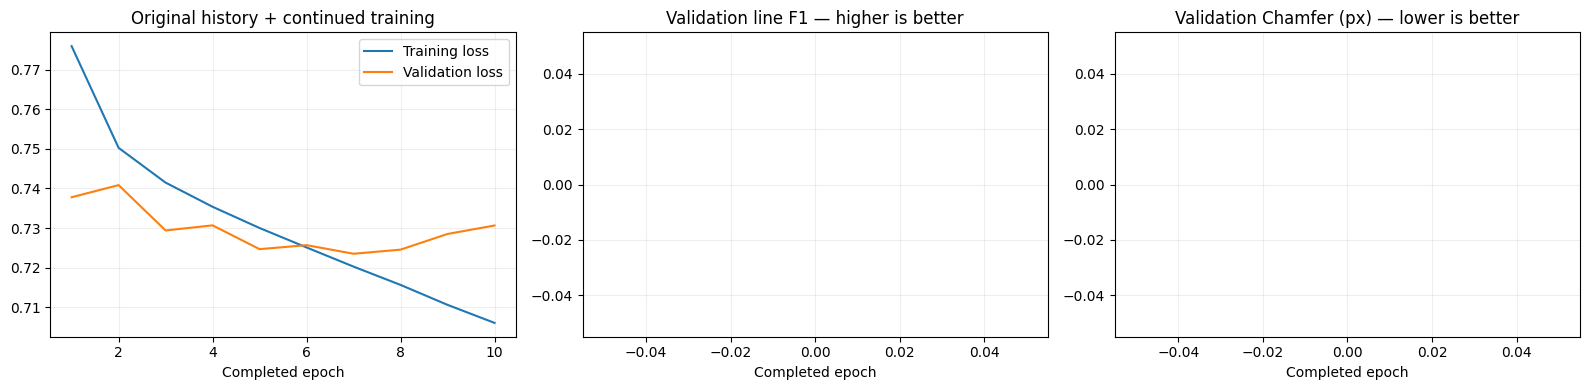

Completed epochs: 10 | best epoch: 7 | best validation loss: 0.7235190272331238


In [19]:
history = run.state["history"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
epochs = [h["epoch"] for h in history]
axes[0].plot(epochs, [h["loss"] for h in history], label="Training loss")
axes[0].plot(epochs, [h["val_loss"] for h in history], label="Validation loss")
axes[0].set_title("Original history + continued training")
axes[0].legend()
quality = [h for h in history if "val_line_f1" in h]
axes[1].plot([h["epoch"] for h in quality], [h["val_line_f1"] for h in quality], "o-")
axes[1].set_title("Validation line F1 — higher is better")
axes[2].plot(
    [h["epoch"] for h in quality], [h["val_chamfer_px"] for h in quality], "o-"
)
axes[2].set_title("Validation Chamfer (px) — lower is better")
for ax in axes:
    ax.set_xlabel("Completed epoch")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(OUT / "training_history.png", dpi=150, bbox_inches="tight")
plt.show()
print(
    "Completed epochs:",
    run.state["completed_epochs"],
    "| best epoch:",
    run.state["best_epoch"],
    "| best validation loss:",
    run.state["best_val"],
    flush=True,
)

## Evaluate the latest checkpoint

With `COMPARE_LATEST=True`, save validation scores for the latest model.

In [20]:
if COMPARE_LATEST:
    latest_summary, latest_folder = run.evaluate(
        run.model,
        split="val",
        label=f"Latest checkpoint (epoch {run.state['completed_epochs']})",
    )
    run.backup()
    print(json.dumps(latest_summary["methods"]["unet"], indent=2))
    print("Latest report:", latest_folder / "summary.json")

Latest checkpoint (epoch 10): 0/29,188 triplets already scored; 29,188 remaining. Fixed baselines are reused.


Latest checkpoint (epoch 10):   0%|          | 0/29188 [00:00<?, ?triplet/s]

Validation scores flushed; refreshing disk backup...
Creating disk backup ZIP...
Backup verified: /content/interframes_stage2_backup.zip (52.5 MiB)
Copying verified backup to Google Drive...
Google Drive backup verified: /content/drive/MyDrive/Interframes/interframes_tf_stage2/models_checkpoints/checkpoint_1795024200603225469.zip
Validation scores flushed; refreshing disk backup...
Creating disk backup ZIP...
Backup verified: /content/interframes_stage2_backup.zip (54.6 MiB)
Copying verified backup to Google Drive...
Google Drive backup verified: /content/drive/MyDrive/Interframes/interframes_tf_stage2/models_checkpoints/checkpoint_1795024534380407458.zip
Validation scores flushed; refreshing disk backup...
Creating disk backup ZIP...
Backup verified: /content/interframes_stage2_backup.zip (57.0 MiB)
Copying verified backup to Google Drive...
Google Drive backup verified: /content/drive/MyDrive/Interframes/interframes_tf_stage2/models_checkpoints/checkpoint_1795024845025897882.zip
Vali

## Evaluate the best checkpoint

Score the lowest-validation-loss checkpoint and display example drawings.

Best epoch 7 val: 0/29,188 triplets already scored; 29,188 remaining. Fixed baselines are reused.


Best epoch 7 val:   0%|          | 0/29188 [00:00<?, ?triplet/s]

Validation scores flushed; refreshing disk backup...
Creating disk backup ZIP...
Backup verified: /content/interframes_stage2_backup.zip (67.0 MiB)
Copying verified backup to Google Drive...
Google Drive backup verified: /content/drive/MyDrive/Interframes/interframes_tf_stage2/models_checkpoints/checkpoint_1795026413969695355.zip
Validation scores flushed; refreshing disk backup...
Creating disk backup ZIP...
Backup verified: /content/interframes_stage2_backup.zip (67.5 MiB)
Copying verified backup to Google Drive...
Google Drive backup verified: /content/drive/MyDrive/Interframes/interframes_tf_stage2/models_checkpoints/checkpoint_1795026635580137986.zip
Validation scores flushed; refreshing disk backup...
Creating disk backup ZIP...
Backup verified: /content/interframes_stage2_backup.zip (68.4 MiB)
Copying verified backup to Google Drive...
Google Drive backup verified: /content/drive/MyDrive/Interframes/interframes_tf_stage2/models_checkpoints/checkpoint_1795026850706470594.zip
Vali

Method,Line F1 ↑,Chamfer px ↓,MAE ↓,Ink fraction
unet,0.791911,1.119570,0.104795,0.140045
copy_start,0.667239,2.341650,0.036016,0.024123
crossfade,0.559747,2.856293,0.033385,0.009831
warp_average,0.588260,3.091442,0.028239,0.009433


Panels: Start | Prediction | True middle | End


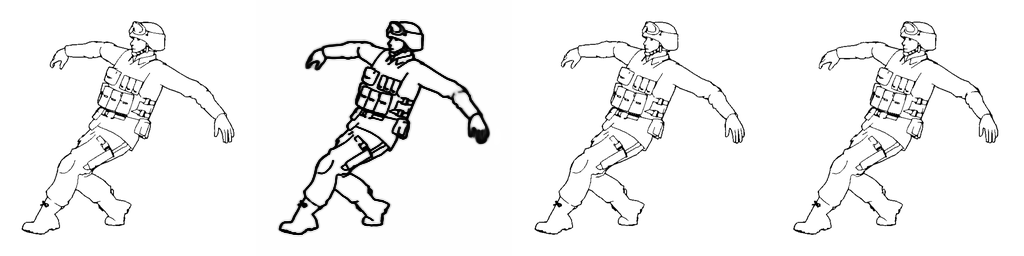

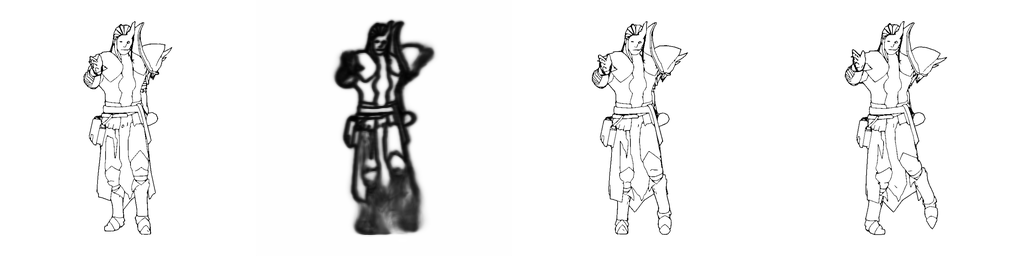

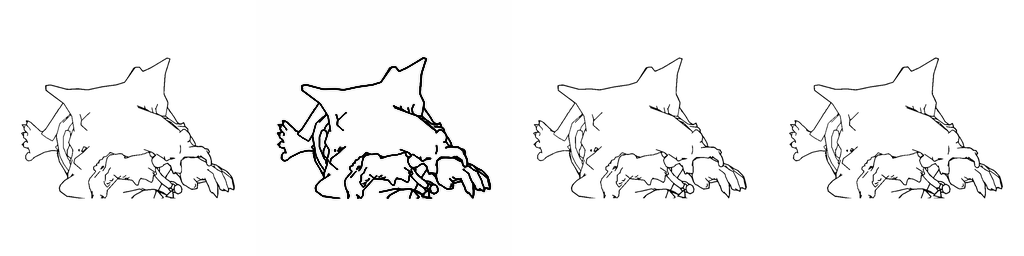

Worst cases: Start | Warp baseline | Prediction | True middle | End
great_sword_slash_maria_w_jj | gap=4 | line F1=0.0931


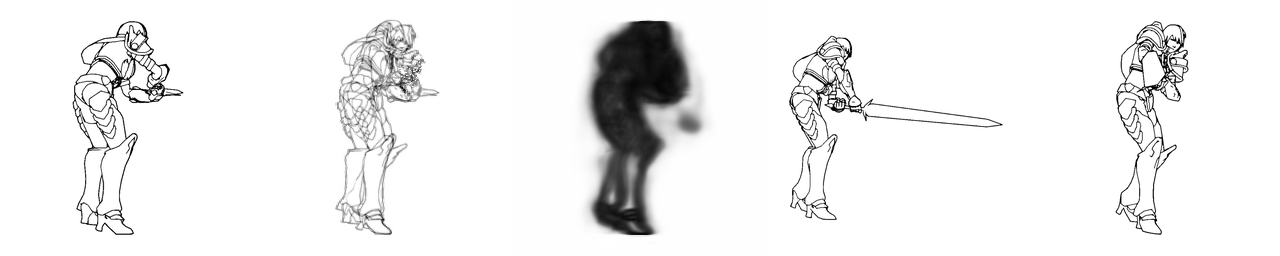

great_sword_slash_maria_w_jj | gap=4 | line F1=0.1600


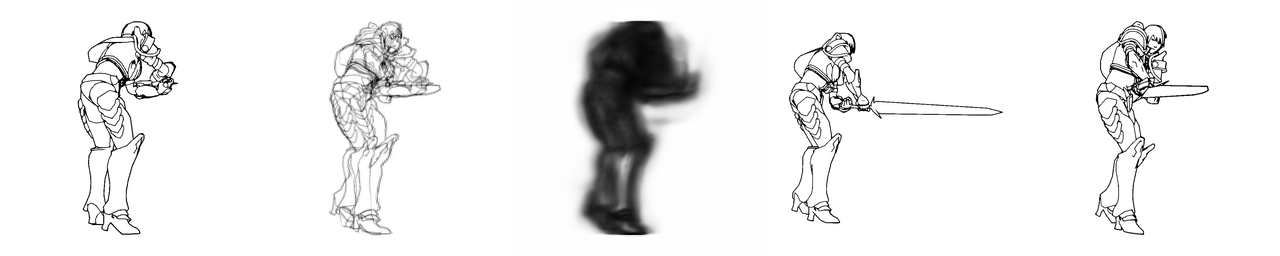

capoeira_warrok | gap=4 | line F1=0.1936


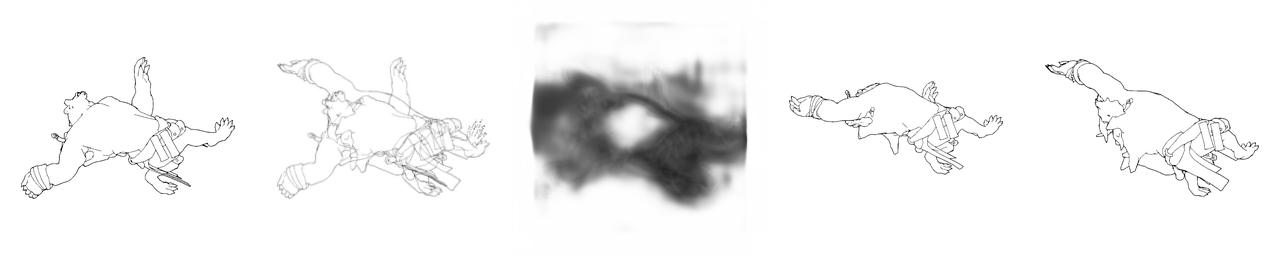

great_sword_slash_maria_w_jj | gap=4 | line F1=0.2028


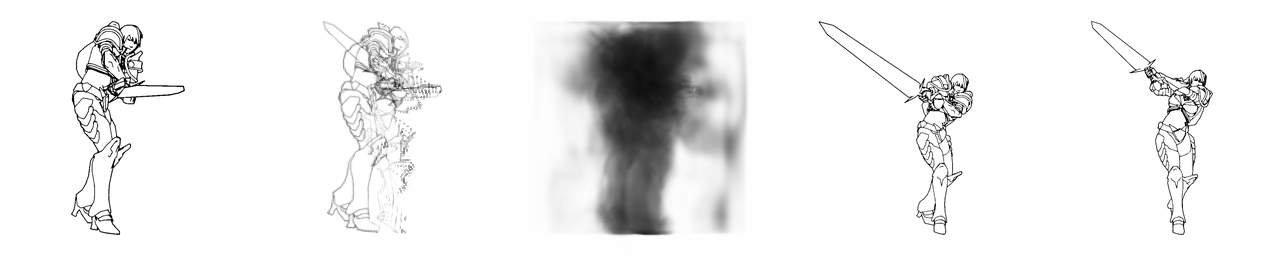

Validation report saved: /content/interframes_tf_stage2/evaluation/val_summary.json


In [21]:
best_model, validation_summary, validation_folder = run.evaluate_best("val")


def show_score_table(summary):
    import html

    rows = []
    for method, values in summary["methods"].items():
        rows.append(
            "<tr><td>"
            + html.escape(method)
            + "</td>"
            + "".join(
                f"<td>{values[k]:.6f}</td>"
                for k in ["line_f1", "chamfer_px", "mae", "ink_fraction"]
            )
            + "</tr>"
        )
    display(
        HTML(
            "<table><tr><th>Method</th><th>Line F1 ↑</th><th>Chamfer px ↓</th>"
            "<th>MAE ↓</th><th>Ink fraction</th></tr>" + "".join(rows) + "</table>"
        )
    )


print("Best checkpoint epoch:", run.state["best_epoch"], flush=True)
show_score_table(validation_summary)
print("Panels: Start | Prediction | True middle | End")
for panel_path in sorted(validation_folder.glob("panel_*.png")):
    display(Image.open(panel_path).copy())
print("Worst cases: Start | Warp baseline | Prediction | True middle | End")
for score in read_json(validation_folder / "worst_cases.json"):
    panel_path = validation_folder / f"failure_{score['id']}.png"
    print(
        f"{score['sequence']} | gap={score['gap']} | line F1={float(score['line_f1']):.4f}"
    )
    if panel_path.exists():
        display(Image.open(panel_path).copy())

quality_output = dict(
    environment=ENVIRONMENT,
    compute_policy=run.compute_policy,
    batch_size=run.batch_size,
    data_fingerprint=meta["fingerprint"],
    best_weights_digest=run.state["best_weights_digest"],
    best_epoch=run.state["best_epoch"],
    completed_epochs=run.state["completed_epochs"],
    validation_summary=str((OUT / "evaluation/val_summary.json").relative_to(OUT)),
    full_validation=True,
    full_recursive_validation=False,
    final_test_run=False,
    animeinbet_comparison_run=False,
    tensorflow=tf.__version__,
    keras=keras.__version__,
)
atomic_json(OUT / "evaluation/stage3_complete.json", quality_output)
print("Validation report saved:", OUT / "evaluation/val_summary.json", flush=True)

## Compare the checkpoints

Export checkpoint scores to CSV; include the latest when enabled.

In [22]:
summaries = [("best.keras", run.state["best_epoch"], validation_summary)]
if COMPARE_LATEST:
    summaries.append(("last.keras", run.state["completed_epochs"], latest_summary))
table = []
for name, epoch, summary in summaries:
    metrics = summary["methods"]["unet"]
    table.append(
        dict(
            checkpoint=name,
            epoch=epoch,
            loss=summary["val_loss"],
            ink_mae=summary["val_ink_mae"],
            line_f1=metrics["line_f1"],
            chamfer_px=metrics["chamfer_px"],
            triplets=summary["n_triplets"],
        )
    )
comparison_path = OUT / "evaluation" / "validation_comparison.csv"
with comparison_path.open("w", newline="") as f:
    writer = csv.DictWriter(f, fieldnames=list(table[0]))
    writer.writeheader()
    writer.writerows(table)
for row in table:
    print(
        "{checkpoint} (epoch {epoch}) | loss {loss:.5f} | MAE {ink_mae:.5f} | F1 {line_f1:.4f} | Chamfer {chamfer_px:.3f} px".format(
            **row
        )
    )
print("Saved:", comparison_path)

best.keras (epoch 7) | loss 0.72352 | MAE 0.09931 | F1 0.7919 | Chamfer 1.120 px
last.keras (epoch 10) | loss 0.73066 | MAE 0.09168 | F1 0.8022 | Chamfer 1.086 px
Saved: /content/interframes_tf_stage2/evaluation/validation_comparison.csv


## Run optional test evaluation

`RUN_TEST=True` scores the best checkpoint on test drawings. Leave off during model selection.

In [23]:
# Optional held-out TEST metrics. Keep RUN_TEST=False while deciding how long to train.
if RUN_TEST:
    _, test_summary, _ = run.evaluate_best("test")
    show_score_table(test_summary)
    quality_output["final_test_run"] = True
    atomic_json(OUT / "evaluation/stage3_complete.json", quality_output)
else:
    print("Held-out test evaluation skipped (RUN_TEST=False).")

Held-out test evaluation skipped (RUN_TEST=False).


## Run optional three-frame previews

Run the enabled three-frame previews or evaluations. Test evaluation requires `RUN_TEST=True`.

In [24]:
if RUN_RECURSIVE_TEST and not RUN_TEST:
    raise ValueError(
        "Set RUN_TEST=True before enabling held-out recursive test evaluation."
    )
if RUN_RECURSIVE_VALIDATION or MAKE_RECURSIVE_PREVIEW or RUN_RECURSIVE_TEST:
    import raft_tf
    import exporting

    recursive_device = "/GPU:0" if device_kind == "GPU" else "/CPU:0"
    recursive_policy = "float32" if device_kind == "TPU" else run.compute_policy
    recursive_folder = (
        OUT
        / "evaluation/recursive"
        / run.state["best_weights_digest"]
        / recursive_policy
    )
    recursive_folder.mkdir(parents=True, exist_ok=True)
    with tf.device(recursive_device):
        if device_kind == "TPU":
            recursive_model, _ = restore_model(
                run.best_path,
                "float32",
                tf.distribute.get_strategy(),
                False,
                training=False,
            )
        else:
            recursive_model = best_model
        motion = raft_tf.RAFTSmallTF(
            DATA_ROOT / "raft_small_tf.npz",
            iterations=int(
                json.loads((DATA_ROOT / "config.json").read_text()).get(
                    "raft_iterations", 12
                )
            ),
        )
        print(
            "Recursive execution:",
            recursive_device,
            "| U-Net policy:",
            recursive_policy,
            flush=True,
        )
        result = recursive_evaluate(
            run,
            recursive_model,
            motion,
            recursive_folder,
            full=RUN_RECURSIVE_VALIDATION,
            preview=MAKE_RECURSIVE_PREVIEW,
        )
        print(result)
        if RUN_RECURSIVE_TEST:
            print(
                recursive_evaluate(
                    run,
                    recursive_model,
                    motion,
                    recursive_folder / "test",
                    full=True,
                    preview=False,
                    split="test",
                )
            )
    quality_output.update(
        full_recursive_validation=RUN_RECURSIVE_VALIDATION,
        full_recursive_test=RUN_RECURSIVE_TEST,
        recursive_preview=MAKE_RECURSIVE_PREVIEW,
        recursive_device=recursive_device,
        recursive_policy=recursive_policy,
    )
    atomic_json(OUT / "evaluation/stage3_complete.json", quality_output)
else:
    print("Optional recursive work skipped; cached midpoint evaluation is complete.")

Optional recursive work skipped; cached midpoint evaluation is complete.


## Save backups and preview animations

Verify backups and show their paths. The remaining cells preview animations at selected ink cutoffs.

In [26]:
run.write_marker()
run.backup()
print(
    "Completed epochs:",
    run.state["completed_epochs"],
    "| Best epoch:",
    run.state["best_epoch"],
)
print("Output folder:", OUT)
print("Local portable ZIP:", BACKUP_ZIP)
if DURABLE_BACKUP_DIR:
    print("Persistent verified backups:", DURABLE_BACKUP_DIR)
    from google.colab import files

    # Uncomment to start a browser download too:
    files.download(str(BACKUP_ZIP))
display(FileLink(str(BACKUP_ZIP)))

Creating disk backup ZIP...
Backup verified: /content/interframes_stage2_backup.zip (82.5 MiB)
Copying verified backup to Google Drive...
Google Drive backup verified: /content/drive/MyDrive/Interframes/interframes_tf_stage2/models_checkpoints/checkpoint_1795027954010939473.zip
Completed epochs: 10 | Best epoch: 7
Output folder: /content/interframes_tf_stage2
Local portable ZIP: /content/interframes_stage2_backup.zip
Persistent verified backups: /content/drive/MyDrive/Interframes/interframes_tf_stage2/models_checkpoints


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/content/interframes_stage2_backup.zip

In [94]:
import json
import random
from tensorflow import keras
from PIL import Image as PILImage, ImageDraw
from IPython.display import Image as NotebookImage, display
import data as raster
import evaluation
import learning
import raft_tf

preview_cases = {}
preview_motion = None


def show_animation(
    split="val", gap=4, seed=42, inbetweens=1, fps=4, ink_cutoff_var=None
):
    global preview_motion

    if inbetweens not in (1, 3):
        raise ValueError("Choose inbetweens=1 or 3.")
    if fps <= 0:
        raise ValueError("FPS must be positive.")
    if ink_cutoff_var is not None and not 0 <= ink_cutoff_var <= 1:
        raise ValueError("Use None for grayscale or a cutoff between 0 and 1.")

    if split not in preview_cases:
        preview_cases[split] = evaluation.recursive_cases(run.root, split)

    choices = [case for case in preview_cases[split] if case[0]["gap"] == gap]
    if not choices:
        raise ValueError(f"No examples for split={split}, gap={gap}. Try gap=2 or 4.")

    row, q1_path, q3_path = random.Random(seed).choice(choices)
    last_epoch = run.state["completed_epochs"]
    best_epoch = run.state["best_epoch"]
    last_model = run.model
    best_model = keras.models.load_model(run.best_path, compile=False)

    print(f"{row['sequence']} | gap {gap} | sample {row['id']}", flush=True)
    print(f"Last: epoch {last_epoch} | Best: epoch {best_epoch}", flush=True)

    start = run.frames.ink(row["a"])
    end = run.frames.ink(row["b"])
    flows = run.frames.flows.get(split)
    if flows is None:
        flows = raster.open_flows(run.root, split)

    if inbetweens == 3 and preview_motion is None:
        print("Loading RAFT for the quarter frames...", flush=True)
        config = json.loads((run.root / "config.json").read_text())
        preview_motion = raft_tf.RAFTSmallTF(
            run.root / "raft_small_tf.npz",
            iterations=int(config.get("raft_iterations", 12)),
        )

    predictions = []
    for model in (last_model, best_model):
        middle = learning.predict_cached(model, run.root, row, flows)
        if inbetweens == 1:
            predictions.append([start, middle, end])
        else:
            q1 = learning.predict_middle(model, preview_motion, start, middle)
            q3 = learning.predict_middle(model, preview_motion, middle, end)
            predictions.append([start, q1, middle, q3, end])

    ref_paths = [row["a"], row["target"], row["b"]]
    if inbetweens == 3:
        ref_paths = [row["a"], q1_path, row["target"], q3_path, row["b"]]

    frames = []
    height, width = start.shape
    headers = [
        f"Last | epoch {last_epoch}",
        f"Best | epoch {best_epoch}",
        "Ground truth",
    ]

    for i, ref_path in enumerate(ref_paths):
        pct = round(100 * i / (len(ref_paths) - 1))
        images = [predictions[0][i], predictions[1][i], run.frames.ink(ref_path)]
        panel = PILImage.new("RGB", (3 * width + 8, height + 26), "white")
        draw = ImageDraw.Draw(panel)

        for col, (ink, header) in enumerate(zip(images, headers)):
            # Only threshold generated drawings. Keep endpoints and references original.
            if col < 2 and 0 < i < len(ref_paths) - 1 and ink_cutoff_var is not None:
                ink = (ink >= ink_cutoff_var).astype("float32")

            x = col * (width + 4)
            panel.paste(raster.ink_image(ink), (x, 26))
            draw.text((x + 5, 6), f"{header} | {pct}%", fill="black")

        frames.append(panel)

    style = "raw" if ink_cutoff_var is None else f"cutoff{ink_cutoff_var:g}"
    folder = OUT / "inference_previews"
    folder.mkdir(parents=True, exist_ok=True)
    # gif = folder / (
    #   f"{split}_{row['id']}_last{last_epoch}_best{best_epoch}_"
    #  f"{inbetweens}mid_{style}.gif"
    # )

    gif = folder / (
        f"{split}_last{last_epoch}_best{best_epoch}_"
        f"{inbetweens}_ink_cutoff{ink_cutoff_var}.gif"
    )
    frames[0].save(
        gif,
        save_all=True,
        append_images=frames[1:],
        duration=max(10, round(1000 / fps)),
        loop=0,
    )
    display(NotebookImage(data=gif.read_bytes(), format="gif"))
    print("Saved:", gif)

freehang_climb_police | gap 4 | sample a978965575676a176c74
Last: epoch 10 | Best: epoch 7


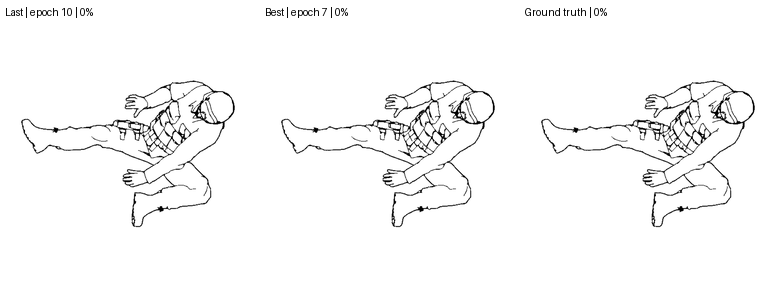

Saved: /content/interframes_tf_stage2/inference_previews/val_last10_best7_1_ink_cutoffNone.gif


In [104]:
show_animation(split="val", gap=4, seed=22, inbetweens=1, fps=2, ink_cutoff_var=None)

freehang_climb_police | gap 4 | sample a978965575676a176c74
Last: epoch 10 | Best: epoch 7


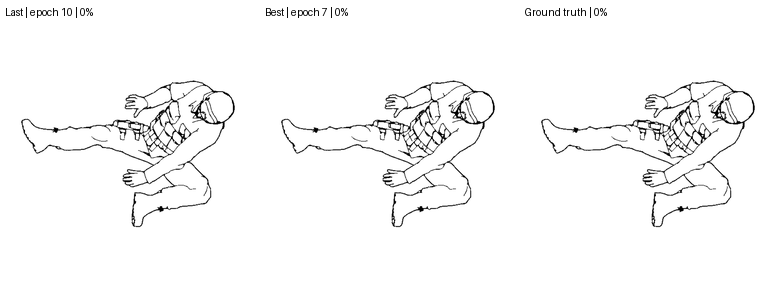

Saved: /content/interframes_tf_stage2/inference_previews/val_last10_best7_1_ink_cutoff0.5.gif


In [103]:
show_animation(split="val", gap=4, seed=22, inbetweens=1, fps=2, ink_cutoff_var=0.50)

freehang_climb_police | gap 4 | sample a978965575676a176c74
Last: epoch 10 | Best: epoch 7


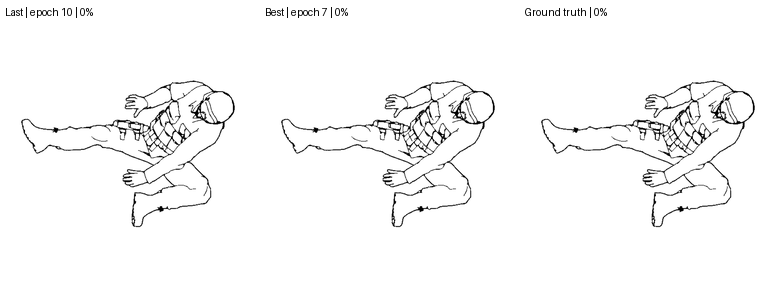

Saved: /content/interframes_tf_stage2/inference_previews/val_last10_best7_1_ink_cutoff0.7.gif


In [102]:
show_animation(split="val", gap=4, seed=22, inbetweens=1, fps=2, ink_cutoff_var=0.70)

freehang_climb_police | gap 4 | sample a978965575676a176c74
Last: epoch 10 | Best: epoch 7


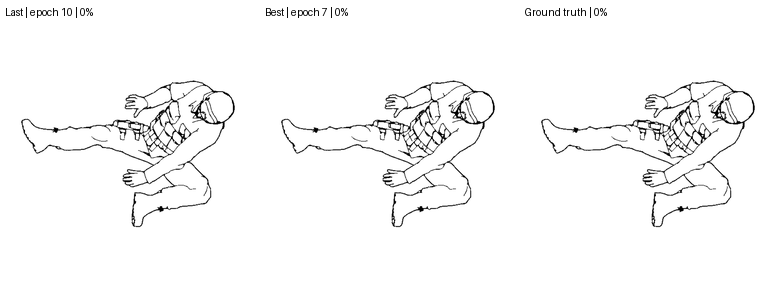

Saved: /content/interframes_tf_stage2/inference_previews/val_last10_best7_1_ink_cutoff0.8.gif


In [101]:
show_animation(split="val", gap=4, seed=22, inbetweens=1, fps=2, ink_cutoff_var=0.80)

fist_fight_a_warrok | gap 4 | sample 5304ddea655d6e2f2222
Last: epoch 10 | Best: epoch 7


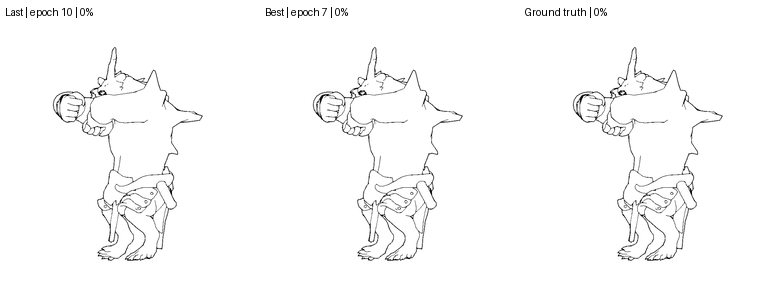

Saved: /content/interframes_tf_stage2/inference_previews/val_last10_best7_1_ink_cutoff0.78.gif


In [108]:
show_animation(split="val", gap=4, seed=42, inbetweens=1, fps=2, ink_cutoff_var=0.78)